In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_excel('../data/telco_customer_churn.xlsx')
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


*Dicionário de Dados*

- CustomerID: Um ID exclusivo que identifica cada cliente.
- Count: Um valor usado em relatórios/painéis para somar o número de clientes em um conjunto filtrado.
- Country: O país de residência principal do cliente.
- State: O estado de residência principal do cliente.
- City: A cidade de residência principal do cliente.
- Zip Code: O código postal (CEP) de residência principal do cliente.
- Lat Long: A combinação de latitude e longitude da residência principal do cliente.
- Latitude: A latitude da residência principal do cliente.
- Longitude: A longitude da residência principal do cliente.
- Gender: O gênero do cliente: Masculino (Male), Feminino (Female).
- Senior Citizen: Indica se o cliente tem 65 anos ou mais: Sim (Yes), Não (No).
- Partner: Indica se o cliente tem um parceiro/cônjuge: Sim (Yes), Não (No).
- Dependents: Indica se o cliente mora com algum dependente: Sim (Yes), Não (No). Os dependentes podem ser filhos, pais, avós, etc.
- Tenure Months: Indica o número total de meses em que o cliente é cliente da empresa até o final do trimestre especificado acima.
- Phone Service: Indica se o cliente assina o serviço de telefonia fixa com a empresa: Sim (Yes), Não (No).
- Multiple Lines: Indica se o cliente assina várias linhas telefônicas com a empresa: Sim (Yes), Não (No).
- Internet Service: Indica se o cliente assina o serviço de internet com a empresa: Não (No), DSL, Fibra Óptica (Fiber Optic), Cabo (Cable).
- Online Security: Indica se o cliente assina um serviço adicional de segurança online fornecido pela empresa: Sim (Yes), Não (No).
- Online Backup: Indica se o cliente assina um serviço adicional de backup online fornecido pela empresa: Sim (Yes), Não (No).
- Device Protection: Indica se o cliente assina um plano adicional de proteção de dispositivos para seus equipamentos de internet fornecido pela empresa: Sim (Yes), Não (No).
- Tech Support: Indica se o cliente assina um plano adicional de suporte técnico da empresa com tempos de espera reduzidos: Sim (Yes), Não (No).
- Streaming TV: Indica se o cliente usa seu serviço de internet para transmitir programação de televisão de um provedor terceirizado: Sim (Yes), Não (No). A empresa não cobra uma taxa adicional por esse serviço.
- Streaming Movies: Indica se o cliente usa seu serviço de internet para transmitir filmes de um provedor terceirizado: Sim (Yes), Não (No). A empresa não cobra uma taxa adicional por esse serviço.
- Contract: Indica o tipo de contrato atual do cliente: Mês a Mês (Month-to-Month), Um Ano (One Year), Dois Anos (Two Year).
- Paperless Billing: Indica se o cliente optou pela fatura sem papel (digital): Sim (Yes), Não (No).
- Payment Method: Indica como o cliente paga sua fatura: Débito bancário/Saque bancário (Bank Withdrawal), Cartão de Crédito (Credit Card), Cheque pelos Correios (Mailed Check).
- Monthly Charges: Indica a cobrança mensal total atual do cliente por todos os seus serviços da empresa.
- Total Charges: Indica as cobranças totais do cliente, calculadas até o final do trimestre especificado acima.
- Churn Label: Sim (Yes) = o cliente deixou a empresa neste trimestre. Não (No) = o cliente permaneceu na empresa. Diretamente relacionado a Churn Value.
- Churn Value: 1 = o cliente deixou a empresa neste trimestre. 0 = o cliente permaneceu na empresa. Diretamente relacionado a Churn Label.
- Churn Score: Um valor de 0 a 100 calculado usando a ferramenta preditiva IBM SPSS Modeler. O modelo incorpora vários fatores conhecidos por causar o cancelamento (churn). Quanto maior a pontuação, maior a probabilidade de o cliente cancelar o serviço.
- CLTV: Valor do Tempo de Vida do Cliente (Customer Lifetime Value). Um CLTV previsto é calculado usando fórmulas corporativas e dados existentes. Quanto maior o valor, mais valioso é o cliente. Clientes de alto valor devem ser monitorados quanto ao cancelamento.
- Churn Reason: O motivo específico de um cliente para deixar a empresa. Diretamente relacionado a Churn Category (Categoria de Churn).

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [ ]:
df['Churn Reason'].value_counts()

Churn Reason
Attitude of support person                   192
Competitor offered higher download speeds    189
Competitor offered more data                 162
Don't know                                   154
Competitor made better offer                 140
Attitude of service provider                 135
Competitor had better devices                130
Network reliability                          103
Product dissatisfaction                      102
Price too high                                98
Service dissatisfaction                       89
Lack of self-service on Website               88
Extra data charges                            57
Moved                                         53
Limited range of services                     44
Lack of affordable download/upload speed      44
Long distance charges                         44
Poor expertise of phone support               20
Poor expertise of online support              19
Deceased                                       6
Name: c

In [5]:
porcentagem_nulos = df['Churn Reason'].isnull().mean() * 100
print(f"Porcentagem de nulos em 'Churn Reason': {porcentagem_nulos:.2f}%\n")

porcentagem_valores_label = df['Churn Label'].value_counts(normalize=True) * 100
print(f"Porcentagem por valor em 'Churn Label':{porcentagem_valores_label.round(2)}")

Porcentagem de nulos em 'Churn Reason': 73.46%

Porcentagem por valor em 'Churn Label':Churn Label
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [48]:
# ValueError: Unable to parse string ' ' at position 2234
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')

In [ ]:
# 1. Quantidade de valores NaN
qtd_nulos_total = df['Total Charges'].isnull().sum()

# 2. Porcentagem de valores NaN em relação ao total de linhas
porcentagem_nulos_total = df['Total Charges'].isnull().mean() * 100

print(f"Quantidade de valores NaN em 'Total Charges': {qtd_nulos_total}")
print(f"Porcentagem de NaN: {porcentagem_nulos_total:.2f}%")

Quantidade de valores NaN em 'Total Charges': 11
Porcentagem de NaN: 0.16%


In [49]:
pp = df[df['Total Charges'].isnull()]
pp[['Monthly Charges', 'Tenure Months', 'Total Charges']]

,Monthly Charges,Tenure Months,Total Charges
2234,52.55,0,NaN
2438,20.25,0,NaN
2568,80.85,0,NaN
2667,25.75,0,NaN
2856,56.05,0,NaN
4331,19.85,0,NaN
4687,25.35,0,NaN
5104,20.00,0,NaN
5719,19.70,0,NaN
6772,73.35,0,NaN


- Monthly Charges: Indica a cobrança mensal total atual do cliente por todos os seus serviços da empresa.
- Tenure Months: Indica o número total de meses em que o cliente é cliente da empresa até o final do trimestre especificado acima.
- Total Charges: Indica as cobranças totais do cliente, calculadas até o final do trimestre especificado acima.
 Logo **Total Charges = Monthly Charges * Tenure Months**

 Porém aparenta que o serviço foi cancelado antes de completar um mês, assumindo que ao cancelar se deve pagar a mensalidade mesmo assim
 Logo **Total Charges = Monthly Charges** quando o **Tenure Months** é **0**

In [ ]:
mask_nulos = df['Total Charges'].isnull()

# df.loc[mask_nulos, 'Total Charges'] = df.loc[mask_nulos, 'Monthly Charges'] * df.loc[mask_nulos, 'Tenure Months']
df.loc[mask_nulos & (df['Tenure Months'] == 0), 'Total Charges'] = df.loc[mask_nulos & (df['Tenure Months'] == 0), 'Monthly Charges']
df['Total Charges'].isnull().sum()

np.int64(0)

Agrupamento por Categoria
1. Concorrência (Competitor)
Motivos associados à perda de clientes para concorrentes com ofertas ou produtos superiores:
- Competitor offered higher download speeds
- Competitor offered more data
- Competitor made better offer
- Competitor had better devices

2. Atendimento ao Cliente (Customer Support & Service)
Motivos ligados à experiência ruim com o suporte técnico ou postura da equipe de atendimento:
- Attitude of support person
- Attitude of service provider
- Poor expertise of phone support
- Poor expertise of online support

3. Qualidade do Produto e Conectividade (Product & Network Quality)
Motivos técnicos, instabilidade de rede ou insatisfação com as funcionalidades do produto/serviço:
- Network reliability
- Product dissatisfaction
- Service dissatisfaction
- Lack of self-service on Website
- Limited range of services

4. Preço e Cobranças (Price & Financial)
Motivos relacionados ao valor cobrado, taxas extras ou custo-benefício da velocidade:
- Price too high
- Extra data charges
- Long distance charges
- Lack of affordable download/upload speed

5. Motivos Pessoais / Mudanças de Vida (Personal Reasons)
Fatores externos ou eventos de vida do cliente onde a empresa pouco pode atuar diretamente:
- Moved
- Deceased

6. Desconhecido / Outros (Unknown):
- Don't know

In [54]:
# Dicionário de mapeamento
mapeamento_categorias = {
    # Concorrência
    'Competitor offered higher download speeds': 'Concorrência',
    'Competitor offered more data': 'Concorrência',
    'Competitor made better offer': 'Concorrência',
    'Competitor had better devices': 'Concorrência',
    
    # Atendimento
    'Attitude of support person': 'Atendimento ao Cliente',
    'Attitude of service provider': 'Atendimento ao Cliente',
    'Poor expertise of phone support': 'Atendimento ao Cliente',
    'Poor expertise of online support': 'Atendimento ao Cliente',
    
    # Qualidade do Produto / Serviço
    'Network reliability': 'Qualidade do Produto e Rede',
    'Product dissatisfaction': 'Qualidade do Produto e Rede',
    'Service dissatisfaction': 'Qualidade do Produto e Rede',
    'Lack of self-service on Website': 'Qualidade do Produto e Rede',
    'Limited range of services': 'Qualidade do Produto e Rede',
    
    # Preço e Custos
    'Price too high': 'Preço e Cobranças',
    'Extra data charges': 'Preço e Cobranças',
    'Long distance charges': 'Preço e Cobranças',
    'Lack of affordable download/upload speed': 'Preço e Cobranças',
    
    # Pessoais
    'Moved': 'Motivos Pessoais',
    'Deceased': 'Motivos Pessoais',
    
    # Desconhecido
    "Don't know": 'Desconhecido'
}

# Criando a nova coluna de Categoria
df['Churn Category'] = df['Churn Reason'].map(mapeamento_categorias)

# Para quem não cancelou (nulos originais do Churn Reason):
df['Churn Category'] = df['Churn Category'].fillna('Cliente Ativo')

# Analisando o impacto por categoria
print(df['Churn Category'].value_counts(normalize=True) * 100)

Churn Category
Cliente Ativo                  73.463013
Concorrência                    8.817265
Qualidade do Produto e Rede     6.048559
Atendimento ao Cliente          5.196649
Preço e Cobranças               3.450234
Desconhecido                    2.186568
Motivos Pessoais                0.837711
Name: proportion, dtype: float64


<Figure size 800x600 with 0 Axes>

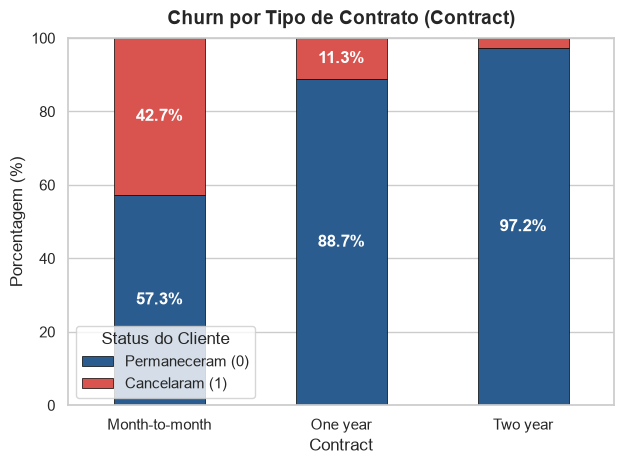

In [60]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 6))
crosstab_contract = pd.crosstab(df['Contract'], df['Churn Value'], normalize='index') * 100
crosstab_contract.columns = ['Permaneceram (0)', 'Cancelaram (1)']

ax = crosstab_contract.plot(
    kind='bar', 
    stacked=True, 
    color=['#2b5c8f', '#d9534f'],
    edgecolor='black',
    linewidth=0.5
)

for p in ax.patches:
    height = p.get_height()
    width = p.get_width()
    x = p.get_x()
    y = p.get_y()
    if height > 5:
        ax.text(x + width / 2, y + height / 2, f'{height:.1f}%', ha='center', va='center', color='white', weight='bold')

plt.title('Churn por Tipo de Contrato (Contract)', fontsize=14, weight='bold', pad=10)
plt.xlabel('Contract', fontsize=12)
plt.ylabel('Porcentagem (%)', fontsize=12)
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Status do Cliente', frameon=True)
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

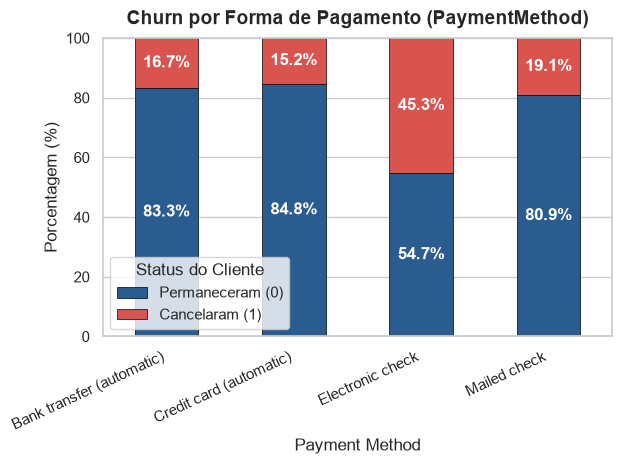

In [63]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
crosstab_payment = pd.crosstab(df['Payment Method'], df['Churn Value'], normalize='index') * 100
crosstab_payment.columns = ['Permaneceram (0)', 'Cancelaram (1)']

ax = crosstab_payment.plot(
    kind='bar', 
    stacked=True, 
    color=['#2b5c8f', '#d9534f'],
    edgecolor='black',
    linewidth=0.5
)

for p in ax.patches:
    height = p.get_height()
    width = p.get_width()
    x = p.get_x()
    y = p.get_y()
    if height > 5:
        ax.text(x + width / 2, y + height / 2, f'{height:.1f}%', ha='center', va='center', color='white', weight='bold')

plt.title('Churn por Forma de Pagamento (PaymentMethod)', fontsize=14, weight='bold', pad=10)
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Porcentagem (%)', fontsize=12)
plt.ylim(0, 100)
plt.xticks(rotation=25, ha='right')
plt.legend(title='Status do Cliente', frameon=True)
plt.tight_layout()
plt.show()

<Figure size 600x600 with 0 Axes>

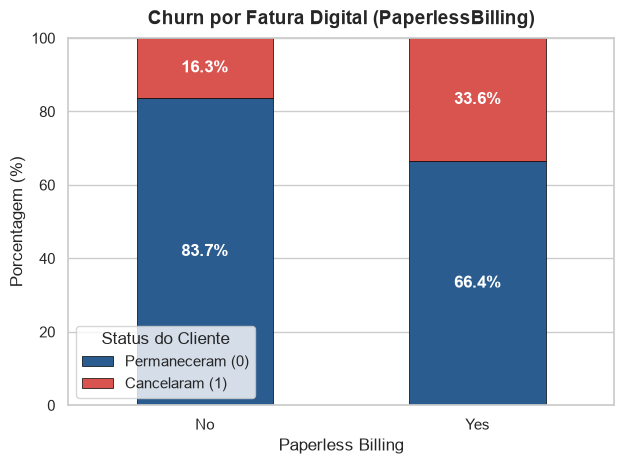

In [65]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(6, 6))
crosstab_paperless = pd.crosstab(df['Paperless Billing'], df['Churn Value'], normalize='index') * 100
crosstab_paperless.columns = ['Permaneceram (0)', 'Cancelaram (1)']

ax = crosstab_paperless.plot(
    kind='bar', 
    stacked=True, 
    color=['#2b5c8f', '#d9534f'],
    edgecolor='black',
    linewidth=0.5
)

for p in ax.patches:
    height = p.get_height()
    width = p.get_width()
    x = p.get_x()
    y = p.get_y()
    if height > 5:
        ax.text(x + width / 2, y + height / 2, f'{height:.1f}%', ha='center', va='center', color='white', weight='bold')

plt.title('Churn por Fatura Digital (PaperlessBilling)', fontsize=14, weight='bold', pad=10)
plt.xlabel('Paperless Billing', fontsize=12)
plt.ylabel('Porcentagem (%)', fontsize=12)
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Status do Cliente', frameon=True)
plt.tight_layout()
plt.show()

C:\Users\danta\AppData\Local\Temp\ipykernel_30112\1696027239.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(frameon=True)


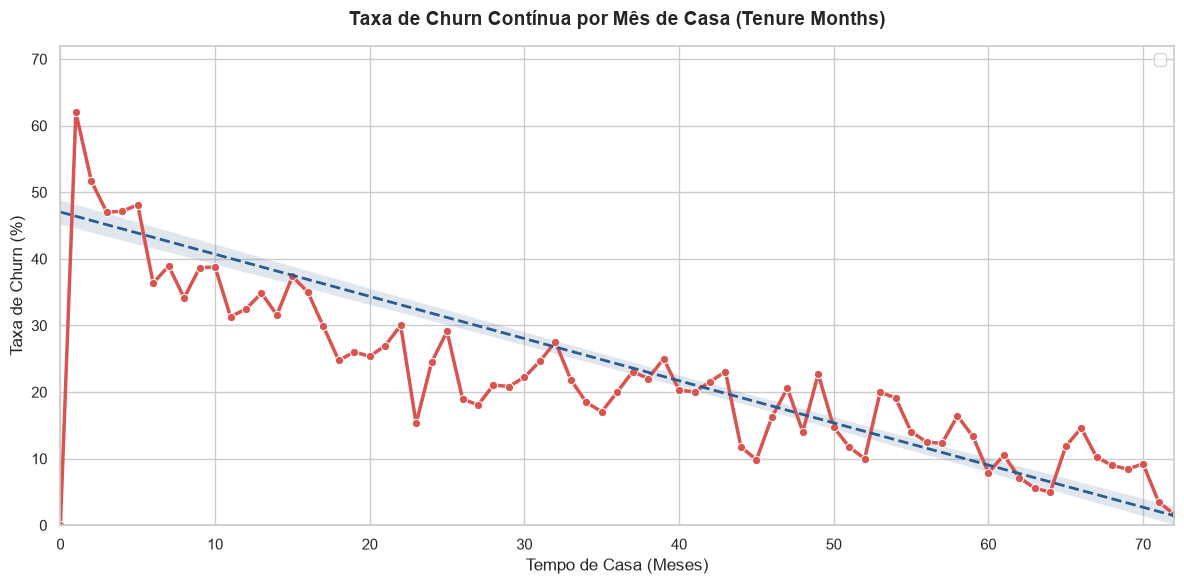

In [67]:
# Ajuste visual geral
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

# 1. Agrupar diretamente por cada mês exato de 'Tenure Months' e calcular a taxa de churn (%)
churn_por_mes = df.groupby('Tenure Months')['Churn Value'].mean() * 100

# 2. Criar um gráfico de linha com pontos marcados
ax = sns.lineplot(
    x=churn_por_mes.index, 
    y=churn_por_mes.values, 
    marker='o', 
    color='#d9534f', 
    linewidth=2.5,
    markersize=6
)

# Opcional: Adicionar uma linha de tendência suave (média móvel ou regressão local) para ver melhor o comportamento geral
sns.regplot(
    x=df['Tenure Months'], 
    y=df['Churn Value'] * 100, 
    scatter=False, 
    color='#2b5c8f', 
    line_kws={'linestyle': '--', 'linewidth': 2, 'label': 'Tendência Geral'},
    ax=ax
)

# Ajustes estéticos
plt.title('Taxa de Churn Contínua por Mês de Casa (Tenure Months)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Tempo de Casa (Meses)', fontsize=12)
plt.ylabel('Taxa de Churn (%)', fontsize=12)
plt.ylim(0, churn_por_mes.max() + 10)
plt.xlim(0, df['Tenure Months'].max())
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

C:\Users\danta\AppData\Local\Temp\ipykernel_30112\3604618773.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Churn Label", y="Tenure Months", data=df, palette="Set2")


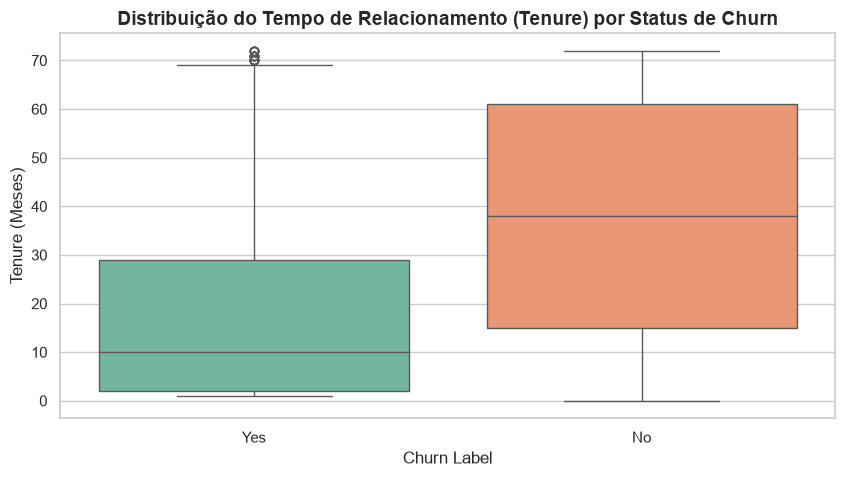

In [99]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="Churn Label", y="Tenure Months", data=df, palette="Set2")
plt.title(
    "Distribuição do Tempo de Relacionamento (Tenure) por Status de Churn",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Churn Label", fontsize=12)
plt.ylabel("Tenure (Meses)", fontsize=12)
plt.show()

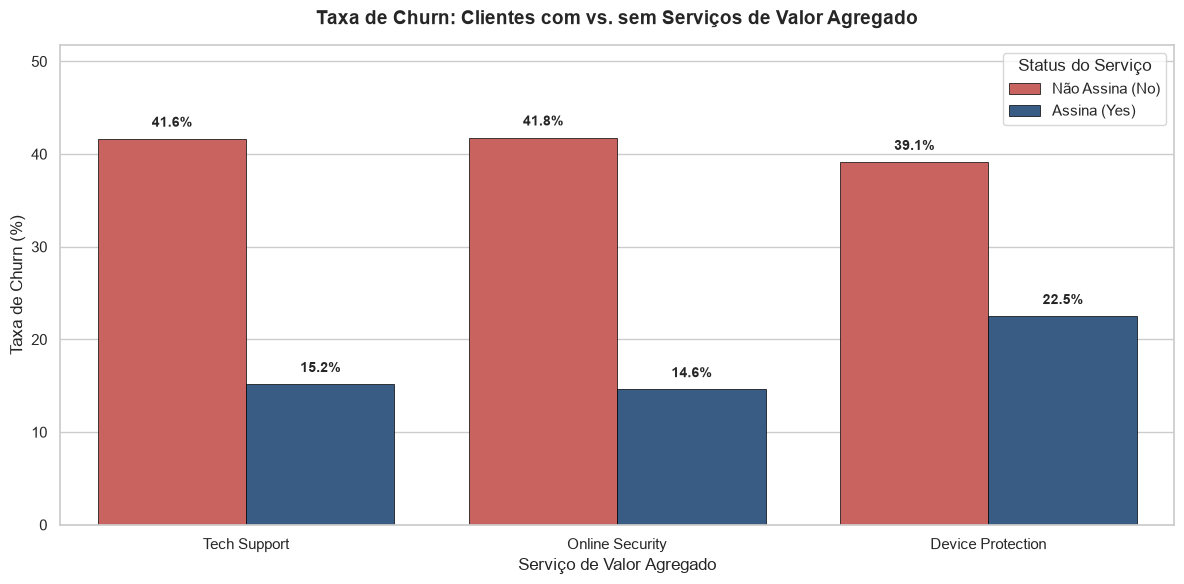

In [69]:
# Ajuste visual geral
sns.set_theme(style="whitegrid")

# 1. Serviços de valor agregado que queremos analisar
servicos = ['Tech Support', 'Online Security', 'Device Protection']

# Filtrar apenas clientes que possuem internet (ignorando quem não tem internet, para evitar distorções)
df_analise = df[df['Internet Service'] != 'No'].copy()

# 2. Consolidar os dados em um formato ideal para plotagem
dados_plot = []
for servico in servicos:
    # Calcula a média do Churn Value (%) para 'Yes' e 'No' em cada serviço
    taxas = df_analise.groupby(servico)['Churn Value'].mean() * 100
    for status, taxa in taxas.items():
        if status in ['Yes', 'No']: # Filtra apenas as respostas válidas de assinatura
            dados_plot.append({
                'Servico': servico,
                'Status_Assinatura': 'Assina (Yes)' if status == 'Yes' else 'Não Assina (No)',
                'Taxa_Churn': taxa
            })

df_plot = pd.DataFrame(dados_plot)

# 3. Plotar o gráfico de barras agrupadas
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_plot,
    x='Servico',
    y='Taxa_Churn',
    hue='Status_Assinatura',
    palette={'Assina (Yes)': '#2b5c8f', 'Não Assina (No)': '#d9534f'},
    edgecolor='black',
    linewidth=0.5
)

# Adicionar os rótulos de porcentagem no topo de cada barra
for p in ax.patches:
    height = p.get_height()
    width = p.get_width()
    x = p.get_x()
    y = p.get_y()
    if height > 0:
        ax.text(
            x + width / 2,
            height + 1,
            f'{height:.1f}%',
            ha='center',
            va='bottom',
            weight='bold',
            fontsize=10
        )

# Ajustes estéticos
plt.title('Taxa de Churn: Clientes com vs. sem Serviços de Valor Agregado', fontsize=14, weight='bold', pad=15)
plt.xlabel('Serviço de Valor Agregado', fontsize=12)
plt.ylabel('Taxa de Churn (%)', fontsize=12)
plt.ylim(0, df_plot['Taxa_Churn'].max() + 10)
plt.legend(title='Status do Serviço', frameon=True)
plt.tight_layout()
plt.show()

C:\Users\danta\AppData\Local\Temp\ipykernel_30112\1541484172.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


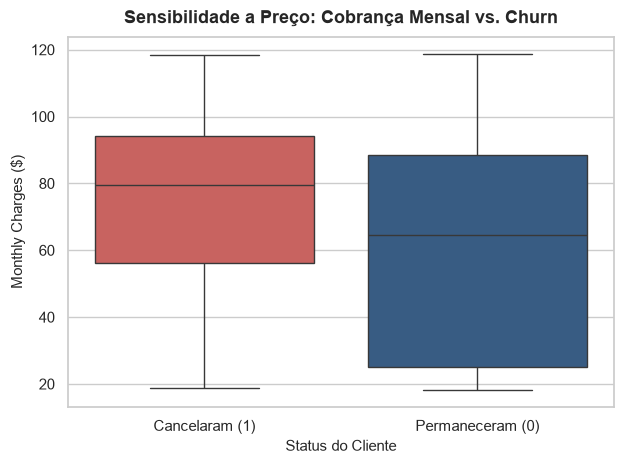

In [74]:
# Ajuste visual geral
sns.set_theme(style="whitegrid")

# 1. Garantir que as colunas financeiras estão no formato numérico
df['Monthly Charges'] = pd.to_numeric(df['Monthly Charges'], errors='coerce')
df['CLTV'] = pd.to_numeric(df['CLTV'], errors='coerce')

# Criar uma coluna legível para o status do churn (para as legendas e eixos)
df['Status_Churn'] = df['Churn Value'].map({0: 'Permaneceram (0)', 1: 'Cancelaram (1)'})

# --- GRÁFICO 1: Boxplot de Monthly Charges vs Churn ---
sns.boxplot(
    data=df,
    x='Status_Churn',
    y='Monthly Charges',
    palette={'Permaneceram (0)': '#2b5c8f', 'Cancelaram (1)': '#d9534f'},
)

plt.title('Sensibilidade a Preço: Cobrança Mensal vs. Churn', fontsize=13, weight='bold', pad=10)
plt.xlabel('Status do Cliente', fontsize=11)
plt.ylabel('Monthly Charges ($)', fontsize=11)

plt.tight_layout()
plt.show()

<Figure size 1200x700 with 0 Axes>

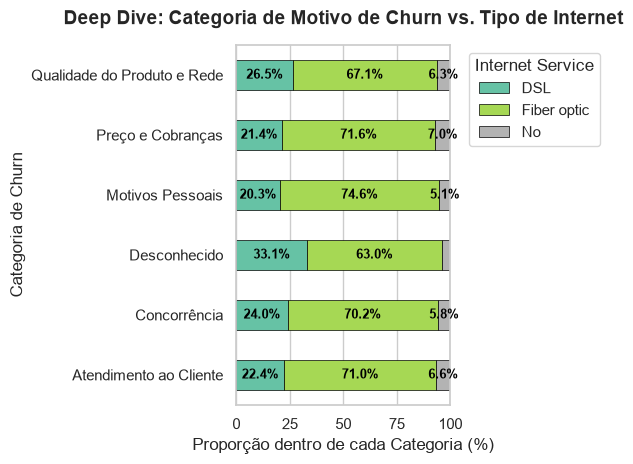

In [76]:
# Ajuste visual geral
sns.set_theme(style="whitegrid")

# 1. Filtrar apenas os clientes que cancelaram (removendo clientes ativos)
# Se você já criou a coluna 'Churn Category', filtramos quem não é 'Cliente Ativo'. 
# Caso contrário, filtramos direto por 'Churn Value == 1'.
if 'Churn Category' in df.columns:
    df_churned = df[df['Churn Category'] != 'Cliente Ativo'].copy()
else:
    df_churned = df[df['Churn Value'] == 1].copy()

# 2. Criar a tabela cruzada entre a Categoria de Churn e o Tipo de Internet (InternetService)
# normalize='index' calcula a porcentagem de cada tipo de internet dentro de cada motivo de churn
crosstab_cat_internet = pd.crosstab(
    df_churned['Churn Category'], 
    df_churned['Internet Service'], 
    normalize='index'
) * 100

# 3. Plotar o Gráfico de Barras Horizontais Empilhadas
plt.figure(figsize=(12, 7))
ax = crosstab_cat_internet.plot(
    kind='barh',
    stacked=True,
    colormap='Set2', # Paleta de cores limpa para categorias
    edgecolor='black',
    linewidth=0.5
)

# Adicionar os rótulos de porcentagem dentro de cada segmento da barra
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x = p.get_x()
    y = p.get_y()
    # Exibe o texto apenas se o bloco for maior que 5% para evitar poluição visual
    if width > 5:
        ax.text(
            x + width / 2,
            y + height / 2,
            f'{width:.1f}%',
            ha='center',
            va='center',
            color='black',
            weight='bold',
            fontsize=9
        )

# Ajustes estéticos
plt.title('Deep Dive: Categoria de Motivo de Churn vs. Tipo de Internet', fontsize=14, weight='bold', pad=15)
plt.xlabel('Proporção dentro de cada Categoria (%)', fontsize=12)
plt.ylabel('Categoria de Churn', fontsize=12)
plt.xlim(0, 100)
plt.legend(title='Internet Service', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

<Figure size 1200x700 with 0 Axes>

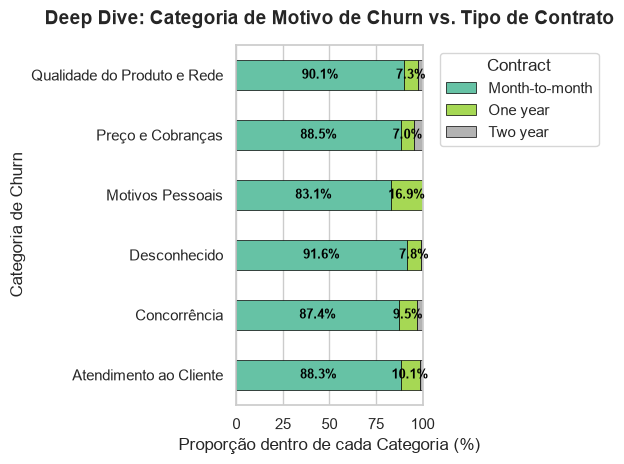

In [78]:
# Ajuste visual geral
sns.set_theme(style="whitegrid")

# 1. Filtrar apenas os clientes que cancelaram (removendo clientes ativos)
# Se você já criou a coluna 'Churn Category', filtramos quem não é 'Cliente Ativo'. 
# Caso contrário, filtramos direto por 'Churn Value == 1'.
if 'Churn Category' in df.columns:
    df_churned = df[df['Churn Category'] != 'Cliente Ativo'].copy()
else:
    df_churned = df[df['Churn Value'] == 1].copy()

# 2. Criar a tabela cruzada entre a Categoria de Churn e o Tipo de Internet (InternetService)
# normalize='index' calcula a porcentagem de cada tipo de internet dentro de cada motivo de churn
crosstab_cat_contract = pd.crosstab(
    df_churned['Churn Category'], 
    df_churned['Contract'], 
    normalize='index'
) * 100

# 3. Plotar o Gráfico de Barras Horizontais Empilhadas
plt.figure(figsize=(12, 7))
ax = crosstab_cat_contract.plot(
    kind='barh',
    stacked=True,
    colormap='Set2', # Paleta de cores limpa para categorias
    edgecolor='black',
    linewidth=0.5
)

# Adicionar os rótulos de porcentagem dentro de cada segmento da barra
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x = p.get_x()
    y = p.get_y()
    # Exibe o texto apenas se o bloco for maior que 5% para evitar poluição visual
    if width > 5:
        ax.text(
            x + width / 2,
            y + height / 2,
            f'{width:.1f}%',
            ha='center',
            va='center',
            color='black',
            weight='bold',
            fontsize=9
        )

# Ajustes estéticos
plt.title('Deep Dive: Categoria de Motivo de Churn vs. Tipo de Contrato', fontsize=14, weight='bold', pad=15)
plt.xlabel('Proporção dentro de cada Categoria (%)', fontsize=12)
plt.ylabel('Categoria de Churn', fontsize=12)
plt.xlim(0, 100)
plt.legend(title='Contract', bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

In [81]:
# 1. Garantir que a coluna de churn numérica existe (0 ou 1)
if 'Churn Value' not in df.columns and 'Churn Label' in df.columns:
    df['Churn Value'] = df['Churn Label'].apply(lambda x: 1 if str(x).strip().lower() in ['yes', '1', 'true'] else 0)

# 2. Agrupar por Cidade e calcular métricas essenciais
cidade_churn = df.groupby('City').agg(
    Total_Clientes=('CustomerID', 'count'),          # Volume de clientes
    Total_Churns=('Churn Value', 'sum')              # Quantidade absoluta de cancelamentos
).reset_index()

# 3. Calcular a Taxa de Churn (%) por cidade
cidade_churn['Taxa_Churn_%'] = (cidade_churn['Total_Churns'] / cidade_churn['Total_Clientes']) * 100

# 4. Ordenar do maior para o menor volume de clientes (para focar nas praças principais)
cidade_churn = cidade_churn.sort_values(by='Total_Clientes', ascending=False)

# Exibir as 15 cidades com maior base de clientes
print(cidade_churn.to_string(index=False))

                  City  Total_Clientes  Total_Churns  Taxa_Churn_%
           Los Angeles             305            90     29.508197
             San Diego             150            50     33.333333
              San Jose             112            29     25.892857
            Sacramento             108            26     24.074074
         San Francisco             104            31     29.807692
                Fresno              64            16     25.000000
            Long Beach              60            15     25.000000
               Oakland              52            13     25.000000
              Stockton              44            12     27.272727
              Glendale              40            13     32.500000
           Bakersfield              40             3      7.500000
             Riverside              32             8     25.000000
              Berkeley              32             9     28.125000
              Whittier              30             5     16.66

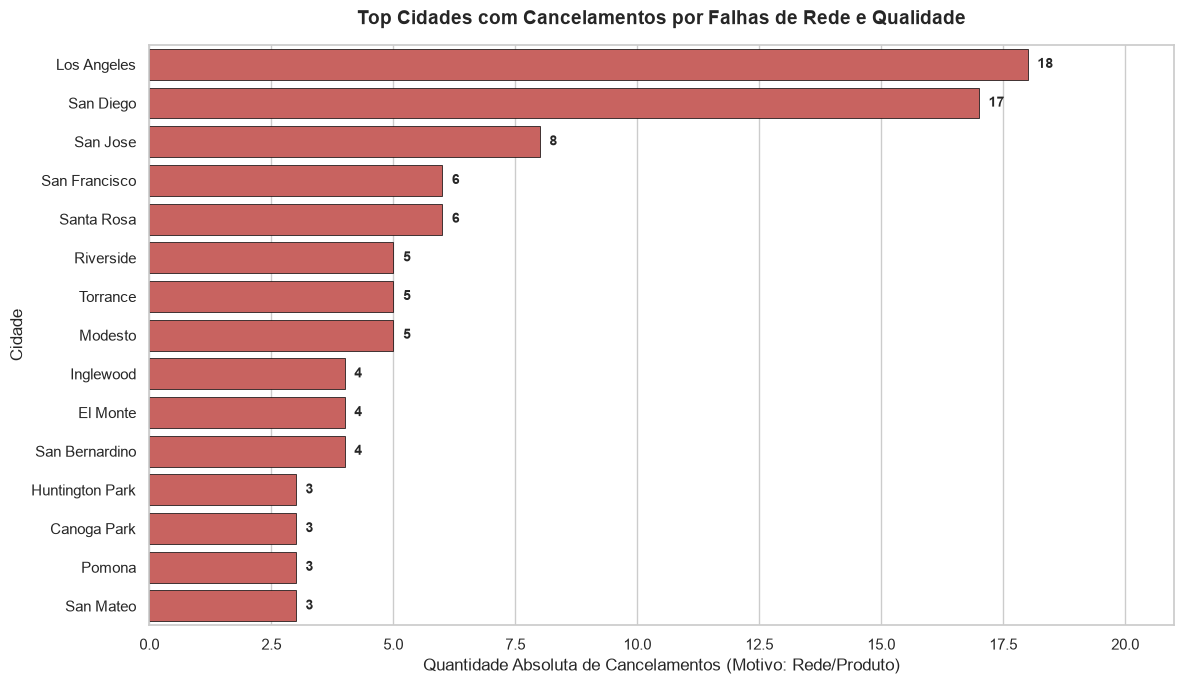

In [82]:
# Ajuste visual geral
sns.set_theme(style="whitegrid")

# 1. Garantir que a coluna 'Churn Category' existe
if 'Churn Category' not in df.columns:
    # Caso ainda não tenha criado, cria o mapeamento básico para o filtro
    mapeamento_categorias = {
        'Network reliability': 'Qualidade do Produto e Rede',
        'Product dissatisfaction': 'Qualidade do Produto e Rede',
        'Service dissatisfaction': 'Qualidade do Produto e Rede',
        'Lack of self-service on Website': 'Qualidade do Produto e Rede',
        'Limited range of services': 'Qualidade do Produto e Rede'
    }
    df['Churn Category'] = df['Churn Reason'].map(mapeamento_categorias).fillna('Outros / Ativos')

# 2. Filtrar apenas os cancelamentos focados em "Qualidade do Produto e Rede"
df_rede = df[df['Churn Category'] == 'Qualidade do Produto e Rede'].copy()

# 3. Contar a quantidade absoluta de cancelamentos por falha de rede em cada cidade
# Pegamos as cidades com maior volume desse problema específico
cidade_problema_rede = df_rede['City'].value_counts().reset_index()
cidade_problema_rede.columns = ['City', 'Qtd_Cancelamentos_Rede']

# Vamos filtrar para exibir as 15 principais cidades com mais problemas de rede
top_cidades_rede = cidade_problema_rede.head(15)

# 4. Plotar o Gráfico de Barras Horizontais
plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=top_cidades_rede,
    x='Qtd_Cancelamentos_Rede',
    y='City',
    color='#d9534f', # Vermelho/Laranja para destacar problemas críticos
    edgecolor='black',
    linewidth=0.5
)

# Adicionar os valores numéricos no final de cada barra
for p in ax.patches:
    width = p.get_width()
    y = p.get_y()
    height = p.get_height()
    if width > 0:
        ax.text(
            width + 0.2, # Posição logo após a barra
            y + height / 2,
            str(int(width)),
            va='center',
            ha='left',
            weight='bold',
            fontsize=10
        )

# Ajustes estéticos
plt.title('Top Cidades com Cancelamentos por Falhas de Rede e Qualidade', fontsize=14, weight='bold', pad=15)
plt.xlabel('Quantidade Absoluta de Cancelamentos (Motivo: Rede/Produto)', fontsize=12)
plt.ylabel('Cidade', fontsize=12)
plt.xlim(0, top_cidades_rede['Qtd_Cancelamentos_Rede'].max() + 3)
plt.tight_layout()
plt.show()

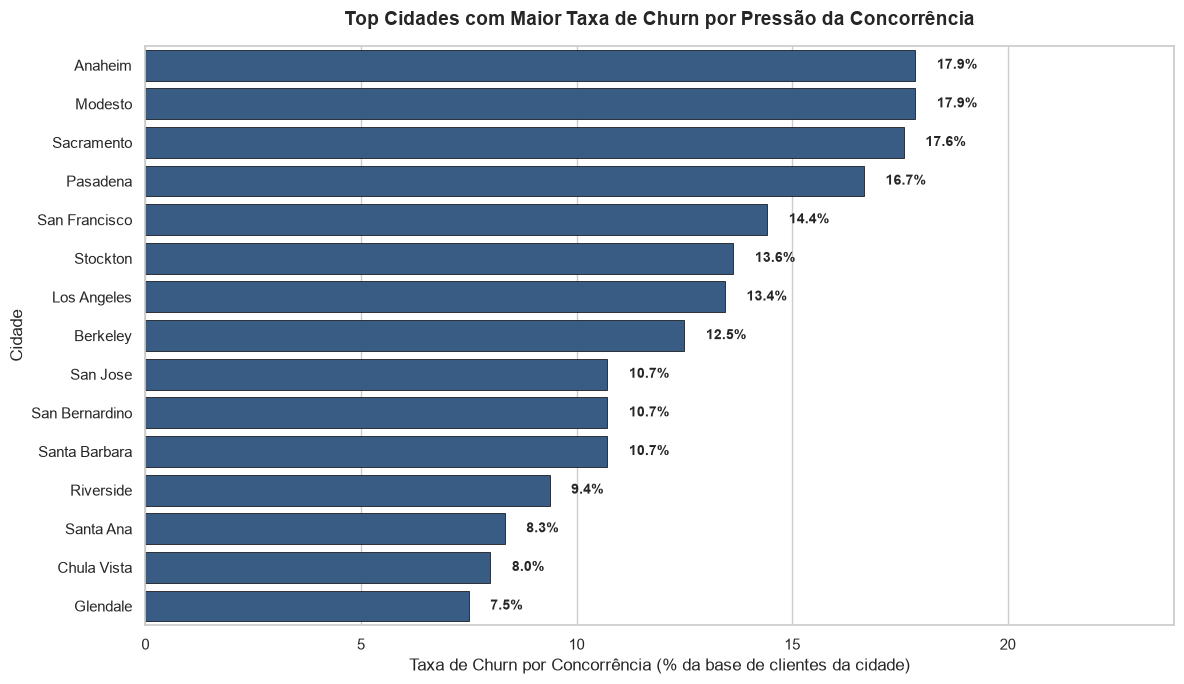

In [83]:
# Ajuste visual geral
sns.set_theme(style="whitegrid")

# 1. Garantir que a coluna 'Churn Category' existe e identifica a concorrência
if 'Churn Category' not in df.columns:
    mapeamento_categorias = {
        'Competitor offered higher download speeds': 'Concorrência',
        'Competitor offered more data': 'Concorrência',
        'Competitor made better offer': 'Concorrência',
        'Competitor had better devices': 'Concorrência'
    }
    df['Churn Category'] = df['Churn Reason'].map(mapeamento_categorias).fillna('Outros / Ativos')

# Criar uma coluna auxiliar indicando se o churn foi motivado por concorrência (1 ou 0)
df['Eh_Concorrencia'] = (df['Churn Category'] == 'Concorrência').astype(int)

# 2. Agrupar por cidade para calcular o total de clientes e quantos saíram por concorrência
cidade_concorrencia = df.groupby('City').agg(
    Total_Clientes=('CustomerID', 'count'),
    Churn_Concorrencia=('Eh_Concorrencia', 'sum')
).reset_index()

# Calcular a taxa de churn por concorrência (%) em relação ao total de clientes daquela cidade
cidade_concorrencia['Taxa_Churn_Concorrencia_%'] = (
    cidade_concorrencia['Churn_Concorrencia'] / cidade_concorrencia['Total_Clientes']
) * 100

# Filtrar apenas cidades com relevância estatística (ex: pelo menos 20 clientes na base)
cidade_relevante = cidade_concorrencia[cidade_concorrencia['Total_Clientes'] >= 20].copy()

# Selecionar as 15 cidades com maior taxa percentual de perda para concorrentes
top_cidades_concorrencia = cidade_relevante.sort_values(
    by='Taxa_Churn_Concorrencia_%', ascending=False
).head(15)

# 3. Plotar o Gráfico de Barras Horizontais
plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=top_cidades_concorrencia,
    x='Taxa_Churn_Concorrencia_%',
    y='City',
    color='#2b5c8f', # Azul corporativo
    edgecolor='black',
    linewidth=0.5
)

# Adicionar os rótulos de porcentagem no final de cada barra
for p in ax.patches:
    width = p.get_width()
    y = p.get_y()
    height = p.get_height()
    if width > 0:
        ax.text(
            width + 0.5,
            y + height / 2,
            f'{width:.1f}%',
            va='center',
            ha='left',
            weight='bold',
            fontsize=10
        )

# Ajustes estéticos
plt.title('Top Cidades com Maior Taxa de Churn por Pressão da Concorrência', fontsize=14, weight='bold', pad=15)
plt.xlabel('Taxa de Churn por Concorrência (% da base de clientes da cidade)', fontsize=12)
plt.ylabel('Cidade', fontsize=12)
plt.xlim(0, top_cidades_concorrencia['Taxa_Churn_Concorrencia_%'].max() + 6)
plt.tight_layout()
plt.show()